# Sparse-scaling benchmark: physical properties

A cell doubled `d` times is still bulk Si, so every property per primitive cell must look the same
at every size. Each figure shows one sparse pipeline. The colored lines are its sizes, and the
dashed black line is the dense reference on the primitive cell (`reference_d00`).

The curves come from [observables.py](observables.py), which normalizes them per primitive cell.
Tensor quantities show the `xx` component. PDOS is left out. A pipeline that does not run a
property has no panel for it: the interior-window pipelines skip doping and the dielectric
tensor, and only `sparse_curvature` gives the Hall coefficient and the effective masses.

A note after each figure explains the curves that do not overlap. Its numbers come from the
`sparse` ladder (d = 0–7) at commit `0708029`.

The offset from the dense reference has two causes, measured at d = 0 on a 16³ mesh. Without
both, the sparse result matches the dense one to 10⁻⁷:

- **The `bond_order 36` cutoff.** It shifts the bands, by up to 0.26 eV at Γ in the lowest band.
  DoS, σ, κ and `cond_xx` move by 2–3%, S and PF by 5%, doping μ by 9 meV, ε″ and ε′ by 8–10%,
  the Hall trace by 15–19% and `inv_mass_dos` by 45%. Every pipeline has this offset at every d.
- **Different sets of bands.** The dense reference sums the interband terms over its `bnd` = 9
  well-projected bands. In the runs here, the sparse pass summed over every solved state: 16 at
  d = 0, 7 of them placeholders at the PAO shift. ε′ and the quantities derived from it then
  differed by 16–79%, even without the cutoff. The sparse engine now drops every state from
  0.2 eV below the shift up (`shift_margin`), so new runs only keep the window effect: fewer real
  conduction bands per cell are solved as d grows. The band-diagonal properties (DoS, transport,
  conductivity, doping) never depended on it.

The notebook reads the output files directly, so it also works while the ladder is still running.

In [9]:
import glob
import os
import sys

import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath('.'))
import observables
from config import CONFIG

ROOT = os.environ.get('BENCH_OUTPUT_ROOT', CONFIG['output_root'])
PIPELINES = [name for name, p in CONFIG['pipelines'].items() if p['enabled'] and p['sparse']]
REFERENCE = 'reference_d00'

# palette: deep blue, vermillion, amber, then Okabe-Ito
PALETTE = ['#004488', '#D55E00', '#FFC20A', '#009E73', '#56B4E9', '#CC79A7', '#000000']
plt.rcParams.update({'font.size': 10, 'axes.grid': True, 'grid.alpha': 0.3})


def load_case(path):
    if not os.path.exists(os.path.join(path, 'record.json')):
        return None
    rec = observables.load_record(path)
    if rec.get('status') != 'ok':
        print('skipping %s: status %s' % (os.path.basename(path), rec.get('status')))
        return None
    return {
        'd': rec['case']['d'],
        'nawf': rec['hamiltonian']['nawf'],
        'curves': observables.load(path, pdos=False, optics=True),
    }


ref_case = load_case(os.path.join(ROOT, REFERENCE))
ref = ref_case['curves'] if ref_case else {}
if not ref:
    print('no finished %s yet: the figures show the sparse sizes only' % REFERENCE)

runs = {}
for pipeline in PIPELINES:
    paths = sorted(glob.glob(os.path.join(ROOT, pipeline + '_d[0-9][0-9]')))
    cases = [c for c in map(load_case, paths) if c is not None]
    if cases:
        runs[pipeline] = cases
        print('%-20s d = %s' % (pipeline, ', '.join(str(c['d']) for c in cases)))

skipping sparse_d09: status running
sparse               d = 0, 1, 2, 3, 4, 5, 6, 7, 8


In [10]:
# name: (title, x label, y label)
LABELS = {
    'dos': ('DoS per primitive cell', 'E - E$_F$ (eV)', 'states/eV'),
    'doping_mu': ('μ at p = 10$^{18}$ cm$^{-3}$', 'T (K)', 'μ (eV)'),
    'sigma_xx': ('σ$_{xx}$/τ', 'μ (eV)', '1/(Ω m s)'),
    'seebeck_xx': ('Seebeck S$_{xx}$', 'μ (eV)', 'V/K'),
    'kappa_xx': ('κ$^{el}_{xx}$/τ', 'μ (eV)', 'W/(m K s)'),
    'pf_xx': ('power factor/τ, xx', 'μ (eV)', 'W/(m K$^2$ s)'),
    'hall_trace': ('Hall tensor trace', 'μ (eV)', ''),
    'cond_xx': ('σ$_{xx}$(E), band-diagonal', 'E - E$_F$ (eV)', ''),
    'cond_xy': ('σ$_{xy}$(E), band-diagonal', 'E - E$_F$ (eV)', ''),
    'epsi_xx': ('ε″$_{xx}$', 'ħω (eV)', ''),
    'epsr_xx': ('ε′$_{xx}$', 'ħω (eV)', ''),
    'eels_xx': ('EELS, -Im 1/ε$_{xx}$', 'ħω (eV)', ''),
    'refl_xx': ('reflectivity R$_{xx}$', 'ħω (eV)', ''),
    'nref_xx': ('refractive index n$_{xx}$', 'ħω (eV)', ''),
    'kref_xx': ('extinction κ$_{xx}$', 'ħω (eV)', ''),
    'alpha_xx': ('absorption α$_{xx}$', 'ħω (eV)', '1/m'),
    'sigmar_xx': ('Re σ$_{xx}$(ω)', 'ħω (eV)', ''),
    'sigmai_xx': ('Im σ$_{xx}$(ω)', 'ħω (eV)', ''),
    'inv_mass_dos': ('Σ g(E - E$_{nk}$) / m$^{dos}_{nk}$', 'E - E$_F$ (eV)', '1/(m$_e$ eV)'),
}


def style(d):
    return dict(color=PALETTE[d % len(PALETTE)], ls=('-', '--', ':')[d // len(PALETTE)], lw=1.1)


def describe(pipeline):
    sc = CONFIG['pipelines'][pipeline].get('sparse_config', {})
    parts = ['bond_order %d' % sc['bond_order']] if 'bond_order' in sc else []
    if 'energy_window' in sc:
        parts.append('states below %.1f eV' % sc['energy_window']['emax'])
    if 'interior_window' in sc:
        w = sc['interior_window']
        parts.append('interior window [%.1f, %.1f] eV' % (w['elo'], w['ehi']))
    return '%s: %s' % (pipeline, ', '.join(parts))


def show(names, ncol=3):
    # one figure per pipeline, one panel per property it ran
    for pipeline, cases in runs.items():
        present = [n for n in names if any(n in c['curves'] for c in cases)]
        if not present:
            continue
        nc = min(ncol, len(present))
        nr = -(-len(present) // nc)
        fig, axes = plt.subplots(nr, nc, figsize=(4.4 * nc, 3.2 * nr), squeeze=False)
        legend = {}
        for ax, name in zip(axes.flat, present):
            curves = [(c, c['curves'][name]) for c in cases if name in c['curves']]
            for c, cv in curves:
                ax.plot(
                    cv['x'], cv['y'], label='d=%d (nawf %d)' % (c['d'], c['nawf']), **style(c['d'])
                )
            if name in ref:
                ax.plot(ref[name]['x'], ref[name]['y'], 'k--', lw=1.0, label='dense reference')
            ax.set_xlim(
                min(cv['x'].min() for _, cv in curves), max(cv['x'].max() for _, cv in curves)
            )
            cuts = [cv['xmax'] for _, cv in curves if cv['xmax'] is not None]
            if cuts:
                ax.axvline(min(cuts), color='#888888', lw=0.8)
            title, xlabel, ylabel = LABELS[name]
            ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
            legend.update(zip(*reversed(ax.get_legend_handles_labels())))
        for ax in axes.flat[len(present) :]:
            ax.axis('off')
        fig.suptitle(describe(pipeline))
        fig.tight_layout()
        fig.legend(
            legend.values(), legend.keys(), loc='center left', bbox_to_anchor=(1.0, 0.5), fontsize=8
        )
        plt.show()

## 1. Density of states and doping

The DoS per primitive cell, and the chemical potential against temperature at a p-type doping of
10¹⁸ cm⁻³. The interior-window DoS covers the window only.

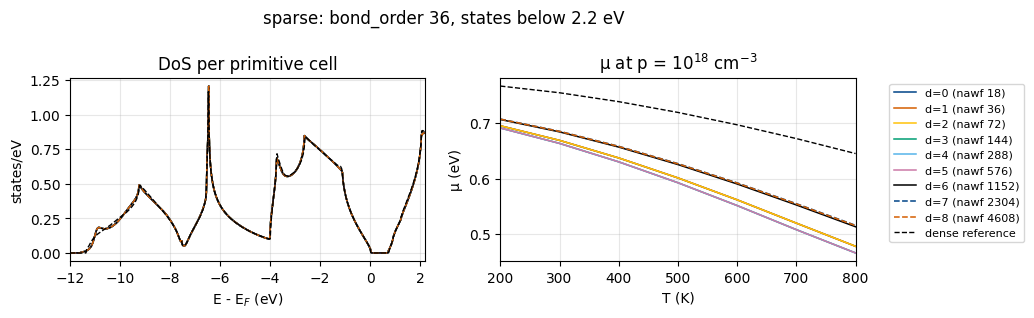

In [11]:
show(['dos', 'doping_mu'], ncol=2)

**Why μ(T) moves with d.** The DoS curves overlap to 5×10⁻⁴. μ splits into three groups
instead: d = 0–2, d = 3–5 (about 0.2 k_BT lower) and d = 6–7 (about 0.6 k_BT higher).

- **μ is set by numerical error, not by the doping.** `do_doping` solves ∫ 2 g(E) f(E) dE =
  nelec − pΩ. At p = 10¹⁸ cm⁻³, pΩ is 4×10⁻⁵ electrons per primitive cell. Integrating the
  DoS on its 14 meV grid already loses 2–3×10⁻⁴ electrons per cell at every d, 5–8 times the
  doping. So μ lands near the conduction-band edge (0.5–0.7 eV) instead of near the valence-band
  top, where a p-type level belongs. Any small change in the DoS then moves it by a fraction of
  k_BT.
- **The DoS change that moves μ is one feature at −7.5 eV.** It appears at d = 3 and changes
  again at d = 6, the sizes where z is doubled (2×2×2 and 4×4×4 primitive cells). From d = 3 on,
  the folded cell maps Si's X and L points onto its own Γ, so their states join larger degenerate
  groups. Inside a group whose velocity blocks do not commute (Si's own multiplets mixed with
  folded copies), the velocities are still paired one direction at a time. That changes the
  adaptive smearing width of a few states. The integrated change is +3×10⁻⁵ electrons at d = 3
  and −1.2×10⁻⁴ at d = 6, the size of the doping itself. This mechanism is a hypothesis that
  has not been checked state by state.
- **Making this a real check:** use p ≳ 10²⁰ cm⁻³ (pΩ ≈ 4×10⁻³), or a much finer energy grid
  for `doping`.

## 2. Boltzmann transport

Constant relaxation time, at 300 K, against the chemical potential. The Hall tensor trace needs
the full spectrum at every k-point, so only `sparse_curvature` has it.

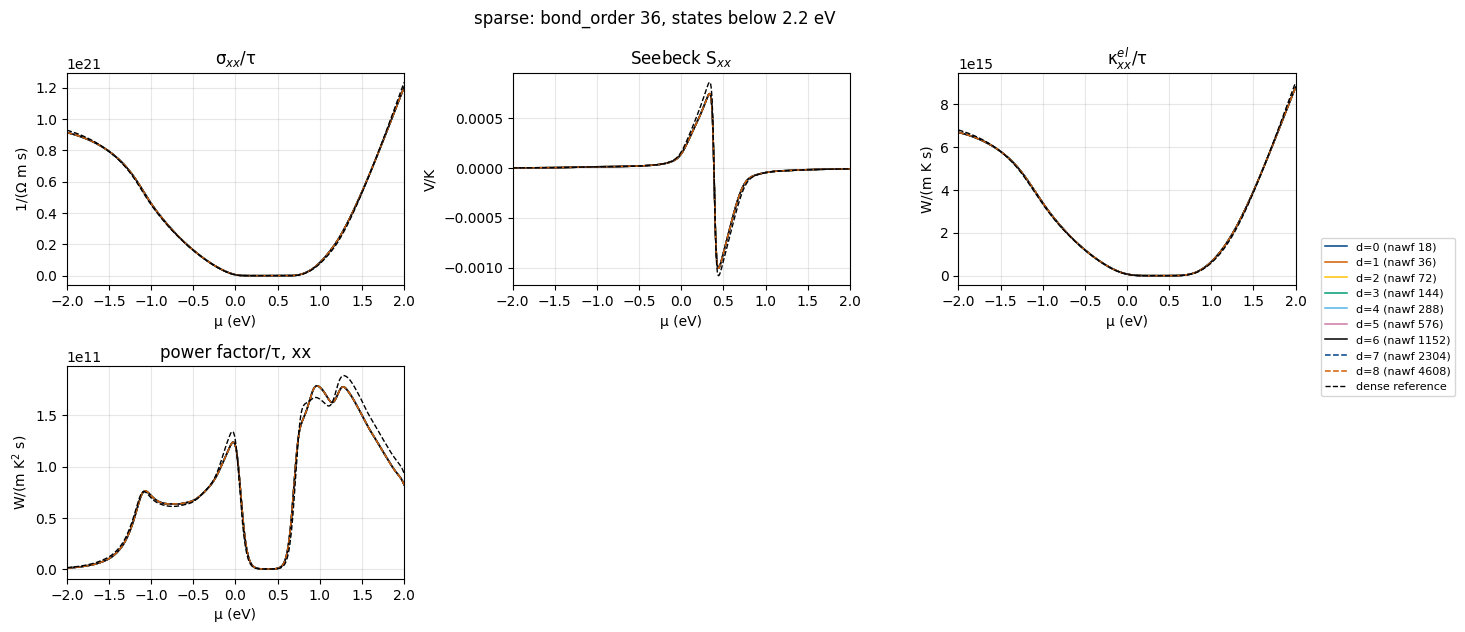

In [12]:
show(['sigma_xx', 'seebeck_xx', 'kappa_xx', 'pf_xx', 'hall_trace'])

σ, S, κ and PF overlap to better than 10⁻⁴ at every d.

**Expected for the Hall trace** (`sparse_curvature`, no local runs yet): drift with d. The band
curvature behind it still diagonalizes each degenerate group one direction at a time (see
`perturb_split`), so on folded cells it can pair curvature components across different states.
A 16³ smoke test at d ≤ 2 gave a 3×10⁻² drift between sizes.

## 3. Band-diagonal conductivity

σ_xy vanishes by cubic symmetry, so its curve should stay at zero next to σ_xx.

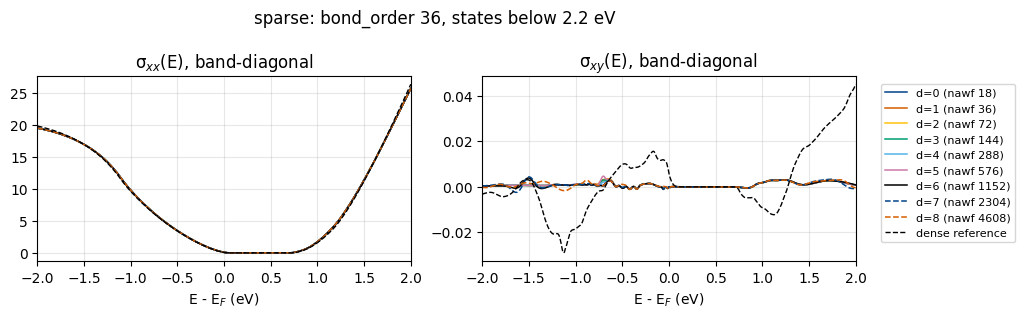

In [13]:
show(['cond_xx', 'cond_xy'], ncol=2)

**Why σ_xy differs between sizes.** σ_xx overlaps to 5×10⁻⁴. σ_xy should vanish by cubic
symmetry, and it is only 1–2×10⁻⁴ of σ_xx at every d, d = 0 included. The panel shows a residual
on its own scale, not a physical signal.

- σ_xy sums v_x v_y over states, so it cancels only if every degenerate group pairs its velocity
  components consistently. Groups whose velocity blocks commute (folded copies) are paired jointly,
  and the others one direction at a time. That leaves a small residual even at d = 0.
- Folding changes which groups are mixed, so the pattern of the residual changes with d. Its size
  does not grow.

## 4. Optical response

Kubo-Greenwood dielectric function and the optical constants built from it. The grey line is the
energy-window top minus 0.5 eV: above it, ε″ of a window run misses the transitions into states
above the window. ε′ and everything derived from it (EELS, R, n, κ, α, σ(ω)) need transitions at
all energies, so for a window run they differ from the reference at every ω.

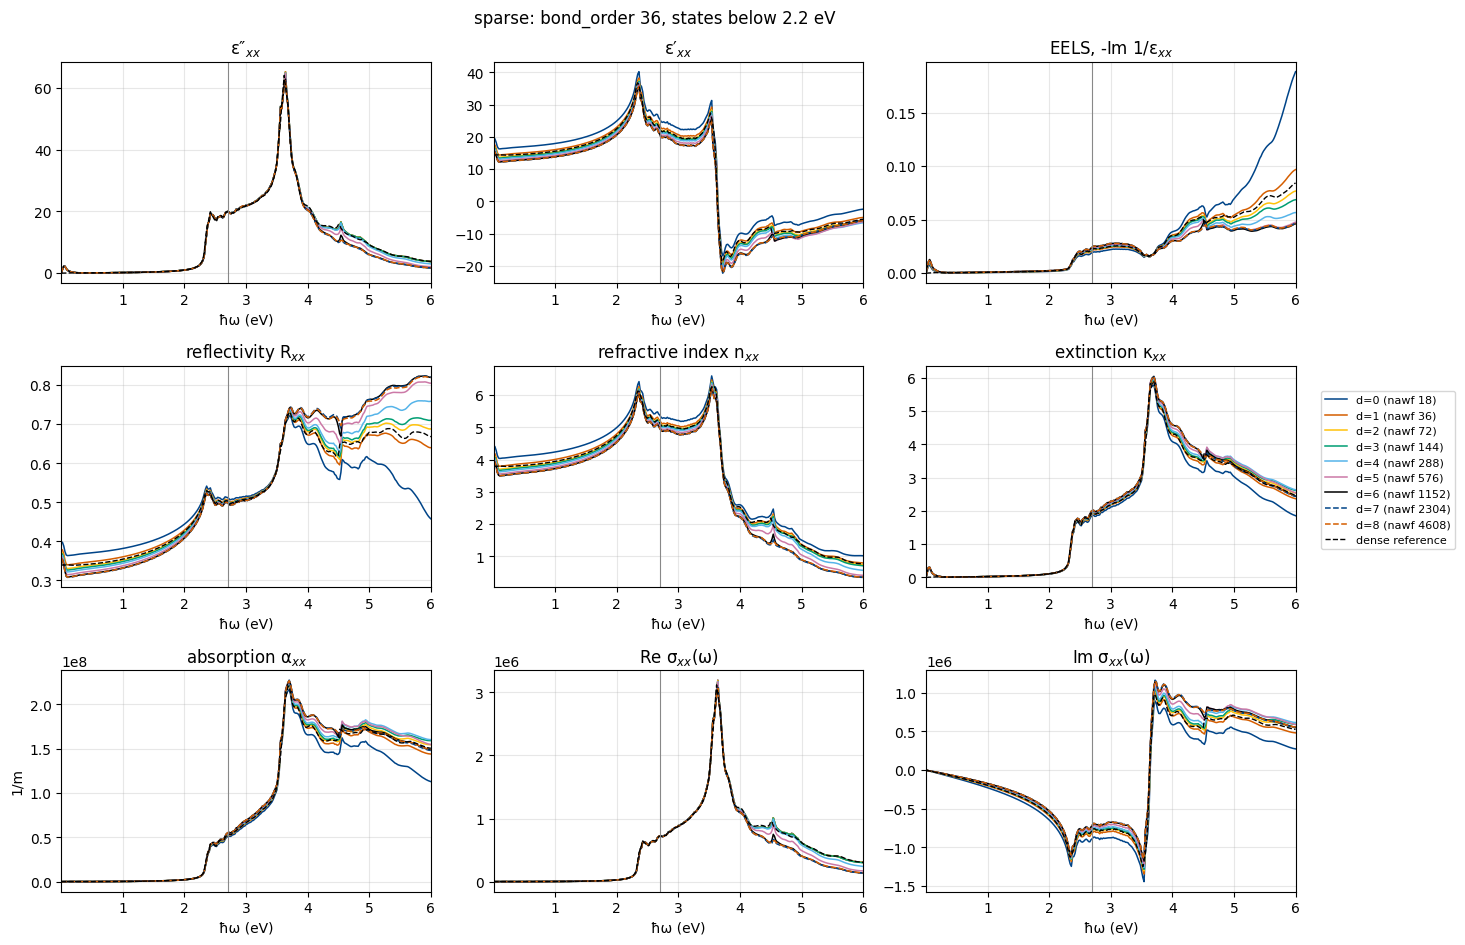

In [14]:
show(
    [
        'epsi_xx',
        'epsr_xx',
        'eels_xx',
        'refl_xx',
        'nref_xx',
        'kref_xx',
        'alpha_xx',
        'sigmar_xx',
        'sigmai_xx',
    ]
)

**Why the optical curves separate.**

- **ε″ above the grey line: the window, not doubling.** The sparse sum runs over every solved
  state, and the solver keeps enough states to reach 3.2 eV at every k-point. Per primitive cell
  that is 16 of 18 states at d = 0 (n = 18 is too small for anything but the dense kernel, so
  nearly everything is solved), 10.5 at d = 1 and 5.4 at d = 7. On a doubled cell, the k-point
  with the most states below the window top sets the count for a whole group of folded k-points,
  so the per-cell count falls toward the average. d = 0 therefore still contains transitions far
  above the window, and each doubling drops more of them. Above the line the curves are not
  expected to agree.
- **ε″ below the line: degenerate groups (fixed after these runs).** The deviation from d = 0
  grows from 4×10⁻⁴ at d = 1 to 4×10⁻³ at d = 7. On a folded cell, `get_degeneracies` sometimes
  listed a group twice, so `perturb_split` rotated it twice. And a group holding copies of a
  multiplet from k and −k had each velocity direction sorted across both copies. Either way, the
  momentum matrix elements and the adaptive pair widths (`delta2`) belonged to different
  states. The mesh pass now merges repeated groups and splits a group into its copies before
  resolving it. On a 16³ test ladder this cut the drift from 5×10⁻³–10⁻² to 1–2×10⁻³, and what
  remains is the window: d = 1 matches d = 0 to 10⁻⁹ once both keep the same states. The
  transitions into states that only d = 0 solves have adaptive Gaussian tails reaching below
  the line.
- **ε′ and everything built from it (EELS, R, n, κ, α, σ(ω)) at every ω.** ε′ at any frequency
  depends on transitions at all energies (Kramers–Kronig). The missing high-energy transitions
  lower it everywhere, more at each d: below 2 eV it is 10% lower at d = 1 and 22% lower at
  d = 7. The derived quantities inherit this.

## 5. Effective masses

The per-state masses of `effective_masses_0.dat` cannot be compared line by line across sizes,
so they are shown as a smeared density of inverse DoS masses, Σ g(E − E_nk) / m_dos,nk, per
k-point of the primitive cell.

In [15]:
show(['inv_mass_dos'], ncol=1)

**Expected** (`sparse_curvature`, no local runs yet): this curve drifts with d.

- It weights each state by 1/m_dos. Near band crossings and band extrema the curvature passes
  through zero, so a small change in the curvature of a few states moves the curve a lot.
- The curvature is paired one direction at a time inside degenerate groups, as described for
  the Hall trace above.

A 16³ smoke test at d ≤ 2 gave a 0.2 relative drift.